# ICU LOS v2 — 02: ekstraksi dan urutan temporal/teks
**Kohort terkunci:** run `20261019_134016_937053_cohort`, 53.044 ICU stay berdasarkan hasil tahap 01 pengguna. Jumlah sebenarnya selalu dibaca dan diverifikasi terhadap metadata run, bukan dipaksakan oleh angka ini.

Notebook mempertahankan **164 pemetaan ITEMID untuk 43 fitur** dari versi 1, lengkap dengan satuan, batas kualitas, agregasi mean/last/sum, deduplikasi dan first-available ownership cairan. Aturan tersebut dicocokkan dengan `mapping_selected.csv` dan `processing_rules.json` pada build versi 1 di PC-mu sebelum memindai raw. Tidak perlu membuat folder `src` atau mengunduh `.py` tambahan.

Prediksi dimulai jam ke-4 lalu setiap jam selama pasien masih di ICU. Slot h memuat informasi baru yang tersedia pada `[INTIME+h, INTIME+h+1 jam)`, dan baru terlihat pada prediksi jam h+1. **Untuk prediksi t, gunakan hanya t slot pertama.** Panjang urutan akhir, OUTTIME, last_prediction_hour dan jumlah titik prediksi tidak boleh menjadi fitur.

Output berupa urutan per stay yang disimpan **sekali**, bukan salinan seluruh riwayat untuk setiap titik prediksi. X statis dan y dari tahap 01 tetap terpisah; notebook ini tidak memuat nilai y untuk pengolahan fitur. Belum ada split, imputasi, normalisasi, tokenisasi, BERT, graf atau training.

## 1. Konfigurasi dan resume
Buka dengan kernel Python proyekmu; dependensi `numpy`, `pandas`, `matplotlib`, dan `IPython` (tersedia pada kernel notebook). Jika perlu: `%pip install numpy pandas matplotlib`.

- **Run pertama:** biarkan `RESUME_RUN = ""`, kemudian Run All. Perhatikan nama run yang tercetak.
- **Jika terputus:** isi `RESUME_RUN` dengan run tahap 02 tersebut, kemudian Run All kembali. Jangan ubah chunk size, kode, atau sumber saat resume.
- Chunk yang sudah di-commit tidak dimasukkan ulang. CSV tetap dipindai untuk melewati chunk lama, sehingga resume tidak selalu langsung mencapai checkpoint.
- Hash seluruh file besar dihitung saat mulai/resume dan progres dicetak. Membaca CHARTEVENTS penuh dapat lama; jangan menyamakan dengan durasi tahap 01.
- Simpan notebook setelah selesai agar tabel dan grafik tetap terlihat. Checkpoint proses disimpan terpisah di SQLite.

Nilai default menemukan build temporal v1 melalui metadata preprocessing v1. Jika lokasi berbeda, isi `V1_TEMPORAL_BUILD` dengan folder **laporan build temporal** yang berisi dua berkas aturan tadi.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from contextlib import contextmanager
import os, json, hashlib, platform, sqlite3, shutil, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path(os.environ.get('ICU_LOS_ROOT',r'C:\Users\ASUS\Documents\icu_los'))
V1_ROOT=Path(os.environ.get('ICU_LOS_V1_ROOT',r'C:\Users\ASUS\Documents\dgt_los'))
RAW_ROOT=Path(os.environ.get('ICU_LOS_RAW_ROOT',str(V1_ROOT/'data'/'raw')))
STAGE01_RUN=os.environ.get('ICU_LOS_STAGE01_RUN','20261019_134016_937053_cohort')
RESUME_RUN=os.environ.get('ICU_LOS_STAGE02_RESUME','')
# Opsional, contoh: Path(r'C:\...\outputs\04_temporal\RUN_build')
V1_TEMPORAL_BUILD=Path(os.environ['ICU_LOS_V1_TEMPORAL_BUILD']) if os.environ.get('ICU_LOS_V1_TEMPORAL_BUILD') else None
CHUNK_SIZE=50000
MAX_STAYS_PER_PARTITION=128
MAX_HOURS_PER_PARTITION=100000
MIN_FREE_GIB=30.0  # cadangan minimum; bukan perkiraan pasti ukuran output
SHOW_LOCAL_TEXT_PREVIEW=False
TABLE_ORDER=['OUTPUTEVENTS','LABEVENTS','CHARTEVENTS','INPUTEVENTS_CV','INPUTEVENTS_MV','NOTEEVENTS']
assert CHUNK_SIZE>0 and 0<MAX_STAYS_PER_PARTITION<=256 and MAX_HOURS_PER_PARTITION>0
print('Project:',ROOT)
print('Tahap 01:',STAGE01_RUN)
print('Resume:',RESUME_RUN or 'run baru')

Project: C:\Users\ASUS\Documents\icu_los
Tahap 01: 20261019_134016_937053_cohort
Resume: run baru


## 2. Aturan fitur versi 1 — dipertahankan, bukan ditetapkan ulang
Sumber port: `step04_temporal_review_v3.py` versi 11 Oktober 2026. Mapping dan aturan klinis di bawah dipertahankan apa adanya lalu dibandingkan dengan build v1 yang benar-benar digunakan pada PC-mu.

GCS memakai last menurut availability, event time, ROW_ID dan key; vital/lab memakai mean; cairan memakai jumlah **recorded volume yang baru tersedia**, bukan estimasi laju atau proporsi volume di tiap jam. Nilai nol yang sah tetap observed. Intubated GCS verbal tidak dikodekan sebagai skor 1. SpO2 `(0,1]` tetap dipertahankan dan ditandai, tidak otomatis dikalikan 100. Aturan kualitas ini mewarisi keterbatasan review versi 1.

In [2]:
MAPPING_ORIGIN_SHA256 = 'd1c339295a5ba655421a5c68c116c61ed494e23fcd31eb600ad940b8e6d7fa0b'

def require(ok, message):
    if not bool(ok):
        raise ValueError(message)

def reference_quality_policy():
    return {
        'version': 'reference_quality_v3',
        'scope': 'source_observation_before_dedup_and_hourly_aggregation',
        'cohort_exclusion': False,
        'replacement': 'none',
        'rules': {
            'chart_glucose': dict(
                upper=500.0, upper_inclusive=False,
                rule_id='glucose_fingerstick_2021',
                references='10.1038/s41597-021-00864-4',
                adaptation='Applied to both CareVue 807 and MetaVision 225664; lower bound remains under review.'),
            'lab_glucose': dict(
                lower=0.0, lower_inclusive=False, upper=1000.0, upper_inclusive=False,
                rule_id='glucose_lab_2021',
                references='10.1038/s41597-021-00864-4;10.1093/jalm/jfae021',
                adaptation='Upper analytical limit from MIMIC-III glucose curation; zero exclusion adapted from serum glucose in MIMIC-IV to blood glucose ITEMIDs 50809 and 50931; positive low values are not corrected.'),
            'sodium': dict(
                lower=10.0, lower_inclusive=True,
                upper=200.0, upper_inclusive=True,
                rule_id='sodium_combined_2024_2019',
                references='10.1093/jalm/jfae021;10.1016/j.jbi.2019.103269',
                adaptation='Lower limit from MIMIC-IV adapted to MIMIC-III; upper limit from ISeeU.'),
            'chloride': dict(
                lower=10.0, lower_inclusive=True,
                rule_id='chloride_lower_2024',
                references='10.1093/jalm/jfae021',
                adaptation='Blood chloride lower reportable limit adapted from MIMIC-IV; legacy upper bound retained and not certified.'),
            'blood_po2': dict(
                upper=800.0, upper_inclusive=True,
                rule_id='blood_po2_upper_2019',
                references='10.1016/j.jbi.2019.103269',
                adaptation='ISeeU measurement upper bound applied to blood pO2 in mmHg; arterial specimen is not assumed; legacy zero policy remains under review.'),
            'blood_ph': dict(
                lower=6.0, lower_inclusive=True,
                upper=None, upper_inclusive=True,
                rule_id='blood_ph_lower_2024',
                references='10.1093/jalm/jfae021',
                adaptation='Lower limit from MIMIC-IV adapted to MIMIC-III; upper limit remains under review.'),
            'urine_recorded_ml': dict(
                lower=0.0, lower_inclusive=True,
                upper=5000.0, upper_inclusive=True,
                rule_id='urine_record_2019',
                references='10.1016/j.jbi.2019.103269',
                adaptation='Applied to each source volume after unit conversion, not to an hourly or daily sum.'),
        },
        'pending': [
            'Glucose lower limit, including source value 0.83 mg/dL.',
            'Blood pH upper limit, including source value 7.81.',
            'SpO2 values 0<value<=1 are retained with an ambiguity ledger; no automatic rescaling.',
            'Zero acceptance is variable-specific; other laboratory zeros remain under review.',
            'Clinical review of other variables and remaining rejected units.',
        ],
    }

def reference_spec_update(spec):
    rules = reference_quality_policy()['rules']
    found = set()

    for s in spec:
        # Pertahankan patch satuan yang sudah diterapkan per ITEMID.
        s['conversions'] = dict(s['conversions'])
        s['reference_rule_id'] = 'legacy_unreviewed'
        s['reference_doi'] = ''

        if s['variable'] in rules:
            rule = rules[s['variable']]
            for key in (
                'lower', 'upper',
                'lower_inclusive', 'upper_inclusive',
            ):
                if key in rule:
                    s[key] = rule[key]

            s['reference_rule_id'] = rule['rule_id']
            s['reference_doi'] = rule['references']
            found.add(s['variable'])

        if s['variable'] == 'chart_glucose':
            require(
                '<missing>' in s['conversions'],
                'Patch satuan glukosa sebelumnya belum ada; '
                'jangan rebuild dahulu.',
            )

    require(
        found == set(rules),
        'Variabel untuk aturan referensi tidak lengkap',
    )
    return spec

def temporal_spec():
    """Spesifikasi v1; ambang tetap, bukan persentil seluruh kohort."""
    aliases = {
        "bpm": {"bpm": (1, 0)},
        "mmHg": {"mmhg": (1, 0), "mm hg": (1, 0)},
        "breaths/min": {"bpm": (1, 0), "insp/min": (1, 0)},
        "%": {"%": (1, 0)},
        "C": {"deg. c": (1, 0), "?c": (1, 0)},
        "F": {
            "deg. f": (1 / 1.8, -32 / 1.8),
            "?f": (1 / 1.8, -32 / 1.8),
        },
        "score": {"<missing>": (1, 0), "points": (1, 0)},
        "mg/dL": {"mg/dl": (1, 0)},
        "mEq/L": {"meq/l": (1, 0), "mmol/l": (1, 0)},
        "K/uL": {"k/ul": (1, 0)},
        "g/dL": {"g/dl": (1, 0)},
        "mmol/L": {"mmol/l": (1, 0)},
        "dimensionless": {"<missing>": (1, 0), "units": (1, 0)},
        "pH": {"units": (1, 0)},
        "mL": {"ml": (1, 0), "cc": (1, 0), "l": (1000, 0)},
    }

    spec = []

    def add(
        table, variable, ids, unit, lo=0, hi=None,
        inclusive=True, agg="mean",
    ):
        for item in ids:
            spec.append(dict(
                source_table=table,
                ITEMID=str(item),
                variable=variable,
                canonical_unit="degC" if unit in ("C", "F") else unit,
                conversions=aliases[unit].copy(),
                lower=lo,
                upper=hi,
                lower_inclusive=inclusive,
                upper_inclusive=(variable == "spo2" or inclusive),
                aggregation=agg,
            ))

    chart = "CHARTEVENTS"

    add(chart, "heart_rate", [211, 220045], "bpm", 0, 300, False)
    add(
        chart, "systolic_bp",
        [51, 442, 455, 6701, 220179, 220050],
        "mmHg", 0, 400, False,
    )
    add(
        chart, "diastolic_bp",
        [8368, 8440, 8441, 8555, 220180, 220051],
        "mmHg", 0, 300, False,
    )
    add(
        chart, "mean_bp",
        [456, 52, 6702, 443, 220052, 220181, 225312],
        "mmHg", 0, 300, False,
    )
    add(
        chart, "respiratory_rate",
        [615, 618, 220210, 224690],
        "breaths/min", 0, 70, False,
    )
    add(chart, "spo2", [646, 220277], "%", 0, 100, False)
    add(chart, "temperature", [676, 223762], "C", 10, 50, False)
    add(
        chart, "temperature", [678, 223761], "F",
        (70 - 32) / 1.8, (120 - 32) / 1.8, False,
    )

    # Fingerstick saja; salinan hasil lab di CHARTEVENTS tidak ditambahkan.
    add(
        chart, "chart_glucose", [807, 225664],
        "mg/dL", 0, None, False,
    )

    for variable, ids, lo, hi in [
        ("gcs_eye", [184, 220739], 1, 4),
        ("gcs_verbal", [723, 223900], 1, 5),
        ("gcs_motor", [454, 223901], 1, 6),
        ("gcs_total_recorded", [198], 3, 15),
    ]:
        add(chart, variable, ids, "score", lo, hi, True, "last")

    # Nilai nol lab dipertahankan; ini adaptasi dari aturan referensi.
    # Blood gas tidak otomatis dianggap sebagai spesimen arterial.
    for variable, ids, unit, hi in [
        ("lab_glucose", [50809, 50931], "mg/dL", 10000),
        ("sodium", [50824, 50983], "mEq/L", 200),
        ("potassium", [50822, 50971], "mEq/L", 30),
        ("chloride", [50806, 50902], "mEq/L", 10000),
        ("bicarbonate", [50882], "mEq/L", 10000),
        ("bun", [51006], "mg/dL", 300),
        ("creatinine", [50912], "mg/dL", 150),
        ("wbc", [51300, 51301], "K/uL", 1000),
        ("hemoglobin", [50811, 51222], "g/dL", 50),
        ("hematocrit", [50810, 51221], "%", 100),
        ("platelets", [51265], "K/uL", 10000),
        ("lactate", [50813], "mmol/L", 50),
        ("albumin", [50862], "g/dL", 10),
        ("bilirubin_total", [50885], "mg/dL", 150),
        ("inr", [51237], "dimensionless", 50),
        ("blood_ph", [50820], "pH", None),
        ("blood_pco2", [50818], "mmHg", None),
        ("blood_po2", [50821], "mmHg", None),
    ]:
        add("LABEVENTS", variable, ids, unit, 0, hi)

    inputs = [
        (
            "crystalloid_recorded_ml",
            [
                30013, 30014, 30015, 30016, 30018, 30020, 30021,
                30060, 30061, 30143, 30159, 30160, 30161, 30176,
            ],
            [
                220949, 220950, 225158, 225159, 225161,
                225823, 225825, 225827, 225828, 225941,
            ],
        ),
        ("colloid_recorded_ml", [30008, 30009], [220862, 220864]),
        (
            "blood_product_recorded_ml",
            [30001, 30005, 30006, 30007],
            [225168, 220970, 225170, 225171],
        ),
        ("oral_recorded_ml", [30056], [226452]),
        ("enteral_flush_recorded_ml", [30059], [226453]),
        (
            "parenteral_nutrition_recorded_ml",
            [30032, 30096], [225916, 225917, 225920],
        ),
    ]

    for variable, cv, mv in inputs:
        for table, ids in [
            ("INPUTEVENTS_CV", cv),
            ("INPUTEVENTS_MV", mv),
        ]:
            add(
                table, variable, ids, "mL",
                agg="sum_newly_available",
            )

    for variable, ids in [
        (
            "urine_recorded_ml",
            [
                40055, 40056, 40057, 40069, 40085, 40094,
                40096, 40405, 40428, 40473, 40651, 40715,
                226557, 226558, 226559, 226560, 226561, 226563,
                226564, 226565, 226567, 226584,
            ],
        ),
        (
            "chest_drain_recorded_ml",
            [
                40076, 40048, 40049, 40050, 40090, 40091, 41707,
                226588, 226589, 226590, 226591, 226592, 226593,
            ],
        ),
        (
            "gastric_recorded_ml",
            [40052, 40059, 40067, 226575, 226576, 226571],
        ),
        (
            "jp_drain_recorded_ml",
            [40071, 40072, 40926, 41683, 226599, 226600, 226597, 226598],
        ),
        ("stool_ostomy_recorded_ml", [40054, 226579, 226582]),
        ("gu_irrigant_in_recorded_ml", [227488]),
        ("gu_irrigant_out_recorded_ml", [227489]),
    ]:
        add(
            "OUTPUTEVENTS", variable, ids, "mL",
            agg="sum_newly_available",
        )
        # Satuan acuan dikonfirmasi pengguna untuk dua ITEMID fingerstick.
    # Hanya dipakai ketika satuan kejadian kosong.
    # Satuan yang terisi tetapi tidak dikenal tetap ditolak.
    for entry in spec:
        if (
            entry["source_table"] == "CHARTEVENTS"
            and entry["ITEMID"] in ("807", "225664")
        ):
            entry["conversions"]["<missing>"] = (1, 0)
            entry["missing_unit_reference"] = "mg/dL"

    return reference_spec_update(spec)

FEATURE_LAYOUT = [
    ('heart_rate','mean','bpm'), ('systolic_bp','mean','mmHg'),
    ('diastolic_bp','mean','mmHg'), ('mean_bp','mean','mmHg'),
    ('respiratory_rate','mean','breaths/min'), ('spo2','mean','%'),
    ('temperature','mean','degC'), ('chart_glucose','mean','mg/dL'),
    ('gcs_eye','last','score'), ('gcs_verbal','last','score'),
    ('gcs_motor','last','score'), ('gcs_total_recorded','last','score'),
    ('lab_glucose','mean','mg/dL'), ('sodium','mean','mEq/L'),
    ('potassium','mean','mEq/L'), ('chloride','mean','mEq/L'),
    ('bicarbonate','mean','mEq/L'), ('bun','mean','mg/dL'),
    ('creatinine','mean','mg/dL'), ('wbc','mean','K/uL'),
    ('hemoglobin','mean','g/dL'), ('hematocrit','mean','%'),
    ('platelets','mean','K/uL'), ('lactate','mean','mmol/L'),
    ('albumin','mean','g/dL'), ('bilirubin_total','mean','mg/dL'),
    ('inr','mean','dimensionless'), ('blood_ph','mean','pH'),
    ('blood_pco2','mean','mmHg'), ('blood_po2','mean','mmHg'),
    ('crystalloid_recorded_ml','sum_newly_available','mL'),
    ('colloid_recorded_ml','sum_newly_available','mL'),
    ('blood_product_recorded_ml','sum_newly_available','mL'),
    ('oral_recorded_ml','sum_newly_available','mL'),
    ('enteral_flush_recorded_ml','sum_newly_available','mL'),
    ('parenteral_nutrition_recorded_ml','sum_newly_available','mL'),
    ('urine_recorded_ml','sum_newly_available','mL'),
    ('chest_drain_recorded_ml','sum_newly_available','mL'),
    ('gastric_recorded_ml','sum_newly_available','mL'),
    ('jp_drain_recorded_ml','sum_newly_available','mL'),
    ('stool_ostomy_recorded_ml','sum_newly_available','mL'),
    ('gu_irrigant_in_recorded_ml','sum_newly_available','mL'),
    ('gu_irrigant_out_recorded_ml','sum_newly_available','mL'),
]

def assert_feature_layout(spec):
    found = {}
    for entry in spec:
        row = (entry['variable'], entry['aggregation'], entry['canonical_unit'])
        require(found.setdefault(entry['variable'], row) == row,
                'Agregasi/satuan berbeda antar-ITEMID')
    require(list(found.values()) == FEATURE_LAYOUT,
            'Urutan/aggregation/unit berbeda dari acuan 43 fitur pengguna')

## 3. Aturan teks dan fungsi integritas
TEXT asli disimpan lokal tanpa perubahan. Normalisasi whitespace hanya untuk hash dan screening. Discharge summary, ISERROR=1, teks kosong, dan pola pernyataan kematian dikeluarkan sesuai keputusan versi 1. Penyebutan LOS dan pemulangan/perpindahan selesai tetap dipertahankan dengan flag. Screening heuristik ini tidak membuktikan bebas kebocoran outcome.

Notes/lab dan event lain dikaitkan menggunakan **seluruh registry ICU raw**, bukan hanya kohort, agar stay di luar kohort tidak menyebabkan pengaitan keliru. Diperlukan satu interval unik untuk pasien/admission pada CHARTTIME/STARTTIME. HADM_ID kosong hanya dapat dikaitkan jika interval pasien unik. Bila ICUSTAY_ID sumber ada, nilainya harus cocok. Kasus tidak unik/konflik dicatat dalam hitungan disposisi, tidak ditebak.

Proxy numerik/notes: maksimum waktu event dan STORETIME bila ada; MV juga menyertakan ENDTIME dan COMMENTS_DATE. LABEVENTS memakai CHARTTIME karena tidak memiliki waktu hasil tersedia. Semua proxy mempunyai keterbatasan klinis.

In [3]:
PATTERNS = {
    "explicit_length_of_stay": r"\b(?:length\s+of\s+stay|(?:icu|hospital)\s+los|los\s*[:=]\s*\d)",
    "completed_disposition": r"\b(?:was|has\s+been|patient\s+was|pt\s+was)\s+(?:discharged|transferred\s+out)\b|\bdischarge\s+(?:date|disposition)\s*:",
    "death_statement": r"\b(?:pronounced\s+dead|time\s+of\s+death|patient\s+(?:died|expired)|pt\s+(?:died|expired))\b",
}
REGEX={k:re.compile(v,re.I) for k,v in PATTERNS.items()}

def clean_text(text):
    # Preserve case, numbers, punctuation, clinical negation and de-ID markers.
    return re.sub(r"\s+", " ", text.replace("\x00", " ")).strip()

## 4. Pembacaan, verifikasi sumber, dan aturan v1

In [4]:
# Streamed extraction engine, inlined into notebook. No project .py dependencies.
def atomic_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    os.replace(tmp, path)


def file_sha(path):
    h = hashlib.sha256(); tick = time.monotonic(); n = 0
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(b); n += len(b)
            if time.monotonic() - tick > 30:
                print(f'  Hash {Path(path).name}: {n/2**30:.2f} GiB', flush=True); tick = time.monotonic()
    return h.hexdigest()


def locate_raw(name):
    hits = [p for p in RAW_ROOT.iterdir() if p.is_file() and p.name.upper() in {name+'.CSV', name+'.CSV.GZ'}]
    require(len(hits) == 1, f'{name}: perlu tepat satu CSV/CSV.GZ; ditemukan {len(hits)}')
    return hits[0]


def read_strings(path, **kw):
    return pd.read_csv(path, dtype='string', keep_default_na=False, encoding='utf-8-sig', on_bad_lines='error', **kw)


def epoch(series):
    parsed = pd.to_datetime(series, format='mixed', errors='coerce')
    result = parsed.to_numpy(dtype='datetime64[s]').astype('int64').astype(float)
    result[parsed.isna().to_numpy()] = np.nan
    return pd.Series(result, index=series.index)


def positive_ids(series, name, allow_blank=False):
    text = series.fillna('').astype(str).str.strip()
    vals = pd.to_numeric(text, errors='coerce')
    good = vals.gt(0) & vals.mod(1).eq(0)
    require((good | (text.eq('') if allow_blank else False)).all(), 'ID tidak valid: '+name)
    return vals


def normalize_spec_row(r):
    def optional_float(x):
        return None if str(x).strip() in ('', 'None', 'nan') or x is None else float(x)
    def boolean(x):
        require(str(x).lower() in ('true','false','1','0'), 'Boolean mapping tidak valid')
        return str(x).lower() in ('true','1')
    conv = json.loads(r['conversions']) if isinstance(r['conversions'], str) else r['conversions']
    return {'source_table':r['source_table'], 'ITEMID':str(r['ITEMID']), 'variable':r['variable'],
            'canonical_unit':r['canonical_unit'], 'aggregation':r['aggregation'],
            'lower':optional_float(r['lower']), 'upper':optional_float(r['upper']),
            'lower_inclusive':boolean(r['lower_inclusive']), 'upper_inclusive':boolean(r['upper_inclusive']),
            'conversions':{str(k):[float(x) for x in v] for k,v in conv.items()}}


def prepare_inputs():
    smpath = ROOT / 'outputs' / STAGE01_RUN / 'run_metadata.json'
    sm = json.loads(smpath.read_text(encoding='utf-8-sig'))
    require(sm['status'] == 'COHORT_COMPLETE_READY_FOR_SEQUENCE_BUILD', 'Tahap 01 belum COMPLETE')
    quality_path = smpath.parent/'quality_checks.csv'
    qc = pd.read_csv(quality_path)
    require(len(qc)>0 and qc.status.eq('PASS').all(), 'Tahap 01 tidak seluruhnya PASS')
    cohort_path = Path(sm['cohort_file']); contract_path = Path(sm['contract_file'])
    require(file_sha(cohort_path)==sm['cohort_sha256'] and file_sha(contract_path)==sm['contract_sha256'], 'Kohort/kontrak tahap 01 berubah')
    contract = json.loads(contract_path.read_text(encoding='utf-8'))
    require(contract['inclusion']=={'minimum_age_years':18, 'ICU_LOS_hours_strictly_greater_than':4}, 'Kriteria kohort berbeda')
    require(contract['prediction']['first_hour']==4 and contract['prediction']['interval_hours']==1, 'Jadwal prediksi berbeda')
    columns=['cohort_row','ICUSTAY_ID','SUBJECT_ID','HADM_ID','INTIME','OUTTIME','first_prediction_hour','last_prediction_hour',
             'DIAGNOSIS','DIAGNOSIS_AVAILABLE_TIME_PROXY','diagnosis_present','diagnosis_available_hour']
    cohort=read_strings(cohort_path,usecols=columns)
    for c in ['cohort_row','ICUSTAY_ID','SUBJECT_ID','HADM_ID','first_prediction_hour','last_prediction_hour']:
        cohort[c]=pd.to_numeric(cohort[c],errors='raise').astype('int64')
    require(np.array_equal(cohort.cohort_row,np.arange(len(cohort))) and cohort.ICUSTAY_ID.is_unique, 'Urutan kohort tidak valid')
    require(len(cohort)==sm['counts']['cohort_stays'], 'Jumlah kohort berbeda')
    cohort['_start']=epoch(cohort.INTIME).astype('int64')
    cohort['_exit']=epoch(cohort.OUTTIME).astype('int64')
    cohort['_cutoff']=cohort._start+cohort.last_prediction_hour*3600
    require((cohort.first_prediction_hour==4).all() and (cohort.last_prediction_hour>=4).all(), 'Jam prediksi invalid')
    require((cohort._cutoff<cohort._exit).all() and (cohort._cutoff+3600>=cohort._exit).all(), 'Jam terakhir tidak sesuai interval ICU')
    sources={name:locate_raw(name) for name in ['ICUSTAYS','D_ITEMS','D_LABITEMS']+TABLE_ORDER}
    registry=read_strings(sources['ICUSTAYS'],usecols=['SUBJECT_ID','HADM_ID','ICUSTAY_ID','INTIME','OUTTIME'])
    for c in ['SUBJECT_ID','HADM_ID','ICUSTAY_ID']:
        registry[c]=positive_ids(registry[c],c).astype('int64')
    require(registry.ICUSTAY_ID.is_unique,'Registry ICU ID duplikat')
    registry['_start']=epoch(registry.INTIME)
    registry['_end']=epoch(registry.OUTTIME)
    regref=registry.set_index('ICUSTAY_ID').reindex(cohort.ICUSTAY_ID)
    require(regref.SUBJECT_ID.notna().all(),'Kohort tidak ditemukan dalam registry')
    for c in ['SUBJECT_ID','HADM_ID']:
        require(np.array_equal(regref[c].to_numpy(),cohort[c].to_numpy()),'Registry tidak cocok: '+c)
    require(np.array_equal(regref._start,cohort._start) and np.array_equal(regref._end,cohort._exit),'Waktu registry tidak cocok')
    registry=registry.loc[registry._start.notna() & (registry._end.isna()|registry._end.gt(registry._start))].copy()
    registry['_end']=registry._end.fillna(9e15)
    registry=registry.rename(columns={'SUBJECT_ID':'_subject','HADM_ID':'_hadm','ICUSTAY_ID':'_icu'})
    registry=registry[['_subject','_hadm','_icu','_start','_end']]
    registry=registry.loc[registry._subject.isin(cohort.SUBJECT_ID)].copy()
    spec=temporal_spec(); assert_feature_layout(spec)
    require(len(spec)==164 and [r[0] for r in FEATURE_LAYOUT]==contract['temporal_features'],'43 fitur berbeda dari tahap 01')
    v1build=V1_TEMPORAL_BUILD
    preprocessing_path=None
    if v1build is None:
        preprocessing_path=V1_ROOT/'outputs'/'06_preprocessing'/'20261011_232105_302785_run'/'run_metadata.json'
        pm=json.loads(preprocessing_path.read_text(encoding='utf-8-sig'))
        require(pm['status']=='COMPLETE','Preprocessing v1 belum COMPLETE')
        v1build=Path(pm['build_run'])
        if not v1build.is_absolute():v1build=V1_ROOT/v1build
    map_path=Path(v1build)/'mapping_selected.csv'
    rules_path=Path(v1build)/'processing_rules.json'
    saved=read_strings(map_path)
    actual={(r['source_table'],str(r['ITEMID'])):normalize_spec_row(r) for r in saved.to_dict('records')}
    expected={(r['source_table'],r['ITEMID']):normalize_spec_row(r) for r in spec}
    require(len(actual)==164 and actual==expected,'Mapping/batas/satuan v1 berbeda dari notebook. Gunakan sumber STEP04 yang tepat; jangan meneruskan dengan fitur berbeda.')
    old_policy=json.loads(rules_path.read_text(encoding='utf-8-sig'))
    require(old_policy.get('reference_quality')==reference_quality_policy(),'Aturan kualitas jurnal v1 berbeda')
    for name,refname in [('D_ITEMS','D_ITEMS'),('D_LABITEMS','D_LABITEMS')]:
        ref=read_strings(sources[name]); ref['ITEMID']=ref.ITEMID.str.strip()
        require(ref.ITEMID.is_unique,'Referensi ITEMID duplikat: '+name)
        ref=ref.set_index('ITEMID')
        for row in spec:
            if (row['source_table']=='LABEVENTS') != (name=='D_LABITEMS'):continue
            require(row['ITEMID'] in ref.index,'ITEMID hilang pada referensi')
            r=ref.loc[row['ITEMID']]
            require(bool(str(r.LABEL).strip()),'Label mapping kosong')
            if name=='D_LABITEMS':require(str(r.FLUID).strip().casefold()=='blood','Lab bukan spesimen blood')
            else:require(str(r.LINKSTO).strip().upper()==row['source_table'],'LINKSTO tidak sesuai')
    inputs={**sources,'stage01_metadata':smpath,'stage01_checks':quality_path,'cohort':cohort_path,'contract':contract_path,
            'v1_mapping':map_path,'v1_processing_rules':rules_path}
    if preprocessing_path:inputs['v1_preprocessing_metadata']=preprocessing_path
    stage01_artifacts={str(Path(a['path']).resolve()):a['sha256'] for a in sm['artifacts']}
    for name,filename in [('X_static','X_static_raw_LOCAL.csv'),('y','y_total_icu_los_days_LOCAL.npy'),('row_map','row_map_LOCAL.csv')]:
        p=Path(sm['data_directory'])/filename
        require(str(p.resolve()) in stage01_artifacts and file_sha(p)==stage01_artifacts[str(p.resolve())],'X/y/row map tahap 01 berubah: '+name)
        inputs['stage01_'+name]=p
    return cohort,registry,spec,inputs,sm

## 5. Checkpoint transaksi, kunci run, dan penyimpanan disk

In [5]:
@contextmanager
def run_lock(path):
    f=open(path,'a+b')
    try:
        if os.name=='nt':
            import msvcrt
            f.seek(0,2)
            if f.tell()==0:f.write(b'0');f.flush()
            f.seek(0);msvcrt.locking(f.fileno(),msvcrt.LK_NBLCK,1)
        else:
            import fcntl
            fcntl.flock(f.fileno(),fcntl.LOCK_EX|fcntl.LOCK_NB)
    except Exception:
        f.close();raise RuntimeError('Run sedang dipakai kernel lain; jangan menjalankan dua proses pada run yang sama.')
    try:yield
    finally:
        if os.name=='nt':
            f.seek(0);msvcrt.locking(f.fileno(),msvcrt.LK_UNLCK,1)
        else:
            fcntl.flock(f.fileno(),fcntl.LOCK_UN)
        f.close()


SCHEMA='''
CREATE TABLE IF NOT EXISTS progress(table_name TEXT PRIMARY KEY,next_chunk INTEGER,counts TEXT,complete INTEGER);
CREATE TABLE IF NOT EXISTS e(k TEXT PRIMARY KEY,source TEXT,icu INTEGER,var TEXT,item INTEGER,val REAL,
 ct INTEGER,et INTEGER,av INTEGER,h INTEGER,rid INTEGER,ord TEXT,status TEXT,cgid TEXT,
 hold TEXT NOT NULL DEFAULT '') WITHOUT ROWID;
CREATE TABLE IF NOT EXISTS lineage(source TEXT,rid INTEGER,icu INTEGER,ct INTEGER,av INTEGER,h INTEGER,
 disposition TEXT,raw_numeric TEXT,raw_unit TEXT,PRIMARY KEY(source,rid)) WITHOUT ROWID;
CREATE TABLE IF NOT EXISTS notes(rid INTEGER PRIMARY KEY,icu INTEGER,source_hadm TEXT,ct INTEGER,av INTEGER,h INTEGER,
 category TEXT,store_missing INTEGER,store_before_chart INTEGER,chartdate_mismatch INTEGER,linkage_method TEXT,
 text_hash TEXT,text TEXT,LOS_flag INTEGER,disposition_flag INTEGER);
CREATE TABLE IF NOT EXISTS intubation(icu INTEGER,h INTEGER,PRIMARY KEY(icu,h)) WITHOUT ROWID;
'''
EVENT_INSERT='''INSERT INTO e(k,source,icu,var,item,val,ct,et,av,h,rid,ord,status,cgid)
VALUES(?,?,?,?,?,?,?,?,?,?,?,?,?,?) ON CONFLICT(k) DO UPDATE SET av=excluded.av,h=excluded.h,rid=excluded.rid
WHERE excluded.av<e.av OR (excluded.av=e.av AND excluded.rid<e.rid)'''

## 6. Ekstraksi kejadian dan pengaitan interval

In [6]:
def terminal(counter,key,n):counter['terminal_'+key]+=int(n)


def link_chunk(frame,table,registry,parent,lookup,counter):
    counter['raw_rows']+=len(frame)
    f=frame.fillna('').copy()
    # TEXT is intentionally not stripped or normalized here.
    for col in f.columns:
        if col!='TEXT':f[col]=f[col].str.strip()
    if table!='NOTEEVENTS':
        choose=f.ITEMID.isin({k[1] for k in lookup if k[0]==table})
        terminal(counter,'outside_mapping',(~choose).sum());f=f.loc[choose].copy()
    subj=pd.to_numeric(f.SUBJECT_ID,errors='coerce')
    choose=subj.isin(set(parent.SUBJECT_ID))
    terminal(counter,'outside_cohort_subject',(~choose).sum());f=f.loc[choose].copy()
    if f.empty:return f
    f['_subject']=positive_ids(f.SUBJECT_ID,'SUBJECT_ID').astype('int64')
    f['ROW_ID']=positive_ids(f.ROW_ID,'ROW_ID').astype('int64')
    f['_source_hadm']=positive_ids(f.HADM_ID,'HADM_ID',True)
    if 'ICUSTAY_ID' in f:f['_source_icu']=positive_ids(f.ICUSTAY_ID,'ICUSTAY_ID',True)
    else:f['_source_icu']=np.nan
    f['_rowpos']=np.arange(len(f),dtype='int64')
    time_col='STARTTIME' if table=='INPUTEVENTS_MV' else 'CHARTTIME'
    f['_ct']=epoch(f[time_col])
    f['_et']=epoch(f.ENDTIME) if table=='INPUTEVENTS_MV' else f['_ct']
    valid=f._ct.notna() & f._et.notna() & f._et.ge(f._ct)
    f['_av']=f[['_ct','_et']].max(axis=1)
    for col in ['STORETIME','COMMENTS_DATE']:
        if col in f:
            parsed=epoch(f[col]);valid &= f[col].eq('')|parsed.notna()
            counter['flag_'+col+'_missing']+=int(f[col].eq('').sum())
            if col=='STORETIME':counter['flag_STORETIME_before_CHARTTIME']+=int(parsed.lt(f._ct).sum())
            f['_av']=pd.concat([f._av,parsed],axis=1).max(axis=1)
    terminal(counter,'invalid_time',(~valid).sum());f=f.loc[valid].copy()
    if f.empty:return f
    candidates=f.merge(registry,on='_subject',how='inner',validate='many_to_many')
    eligible=(candidates._ct.ge(candidates._start)&candidates._ct.lt(candidates._end)&
              (candidates._source_hadm.isna()|candidates._source_hadm.eq(candidates._hadm)))
    candidates=candidates.loc[eligible].copy()
    multiplicity=candidates.groupby('_rowpos').size()
    singleton=set(multiplicity.index[multiplicity.eq(1)])
    terminal(counter,'no_unique_registry_interval',len(f)-len(singleton))
    f=candidates.loc[candidates._rowpos.isin(singleton)].copy()
    choose=f._icu.isin(parent.index)
    terminal(counter,'linked_stay_outside_cohort',(~choose).sum());f=f.loc[choose].copy()
    conflict=f._source_icu.notna()&f._source_icu.ne(f._icu)
    terminal(counter,'source_ICUSTAY_ID_conflict',conflict.sum());f=f.loc[~conflict].copy()
    if f.empty:return f
    cutoff=f._icu.map(parent._cutoff)
    choose=f._av.lt(cutoff)
    terminal(counter,'not_available_before_last_prediction',(~choose).sum());f=f.loc[choose].copy()
    if f.empty:return f
    f['_h']=((f._av-f._start)//3600).astype('int64')
    require(f._h.ge(0).all() and f._h.lt(f._icu.map(parent.last_prediction_hour)).all(),'Jam event invalid')
    return f


def process_chunk(db,frame,table,registry,parent,lookup,counter):
    f=link_chunk(frame,table,registry,parent,lookup,counter)
    if f.empty:return
    if table=='NOTEEVENTS':
        rows=[];logs=[]
        f['_store_epoch']=epoch(f.STORETIME)
        f['_chartdate_epoch']=epoch(f.CHARTDATE) if 'CHARTDATE' in f else np.nan
        f['_date_mismatch']=f._chartdate_epoch.notna()&((f._chartdate_epoch//86400)!=(f._ct//86400))
        for r in f.to_dict('records'):
            rid=int(r['ROW_ID']);icu=int(r['_icu']);reason=''
            text=str(r['TEXT']);category=r['CATEGORY'];error=r['ISERROR']
            if category.casefold()=='discharge summary':reason='discharge_summary'
            elif error=='1':reason='ISERROR_1'
            elif error not in ('','0'):reason='invalid_ISERROR'
            elif not category:reason='missing_category'
            elif not text.strip():reason='blank_TEXT'
            elif REGEX['death_statement'].search(clean_text(text)):reason='death_statement'
            if reason:
                terminal(counter,'note_excluded_'+reason,1)
            else:
                terminal(counter,'note_accepted',1)
                cleaned=clean_text(text)
                hsh=hashlib.sha256(cleaned.encode('utf-8')).hexdigest()
                mismatch=int(r['_date_mismatch'])
                before=int(np.isfinite(r['_store_epoch']) and r['_store_epoch']<r['_ct'])
                rows.append((rid,icu,r['HADM_ID'],int(r['_ct']),int(r['_av']),int(r['_h']),category,
                             int(not r.get('STORETIME','')),before,mismatch,
                             'subject_interval_missing_hadm' if not r['HADM_ID'] else 'subject_admission_interval',
                             hsh,text,int(bool(REGEX['explicit_length_of_stay'].search(cleaned))),
                             int(bool(REGEX['completed_disposition'].search(cleaned)))))
            logs.append((table,rid,icu,int(r['_ct']),int(r['_av']),int(r['_h']),reason or 'accepted','',''))
        db.executemany('INSERT INTO lineage VALUES(?,?,?,?,?,?,?,?,?)',logs)
        db.executemany('INSERT INTO notes VALUES('+','.join('?'*15)+')',rows)
        return
    events=[];logs=[];intubations=[]
    field='AMOUNT' if table.startswith('INPUT') else 'VALUE' if table=='OUTPUTEVENTS' else 'VALUENUM'
    ufield='AMOUNTUOM' if table.startswith('INPUT') else 'VALUEUOM'
    for r in f.to_dict('records'):
        s=lookup[table,r['ITEMID']];var=s['variable'];reason=''
        if table=='CHARTEVENTS' and r['ERROR'] not in ('','0','1'):reason='error_flag_invalid'
        elif table=='CHARTEVENTS' and r['ERROR']=='1':reason='ERROR_1'
        elif table=='INPUTEVENTS_MV' and r['STATUSDESCRIPTION'].casefold()=='rewritten':reason='Rewritten'
        elif var=='gcs_verbal' and r.get('VALUE','').casefold() in ('1.0 et/trach','no response-ett'):
            reason='gcs_intubated_not_score_1';intubations.append((int(r['_icu']),int(r['_h'])))
        unit=r[ufield].casefold() or '<missing>'
        if not reason and unit not in s['conversions']:reason='unit_not_allowed'
        try:value=float(r[field])
        except (TypeError,ValueError):value=float('nan')
        if not reason and not np.isfinite(value):reason='numeric_missing_or_nonfinite'
        if not reason:
            scale,offset=s['conversions'][unit];value=value*scale+offset
            if not np.isfinite(value):reason='numeric_nonfinite_after_conversion'
            elif ((value<s['lower'] if s['lower_inclusive'] else value<=s['lower']) or
                  (s['upper'] is not None and (value>s['upper'] if s['upper_inclusive'] else value>=s['upper']))):reason='outside_fixed_bounds'
            elif var.startswith('gcs_') and not value.is_integer():reason='gcs_not_integer'
        order=r.get('ORDERID','')
        if not reason and table.startswith('INPUT') and not re.fullmatch(r'[1-9][0-9]*',order):reason='ORDERID_missing_or_invalid'
        rid=int(r['ROW_ID']);icu=int(r['_icu']);av=int(r['_av']);h=int(r['_h'])
        logs.append((table,rid,icu,int(r['_ct']),av,h,reason or 'valid_before_dedup',r[field],r[ufield]))
        if reason:
            terminal(counter,'quality_rejected',1);counter['reject_'+reason]+=1;continue
        terminal(counter,'temporal_valid_before_dedup',1)
        value=0.0 if value==0 else value
        status=r.get('STATUSDESCRIPTION',r.get('FLAG',r.get('STOPPED','')));cgid=r.get('CGID','')
        # Same identity components as v1; canonical timestamps encode the same instants.
        ct=pd.Timestamp(int(r['_ct']),unit='s').strftime('%Y-%m-%d %H:%M:%S')
        et=pd.Timestamp(int(r['_et']),unit='s').strftime('%Y-%m-%d %H:%M:%S')
        identity=[table,str(icu),r['ITEMID'],ct,et,value.hex(),order,status,cgid]
        key=hashlib.sha256(json.dumps(identity,separators=(',',':')).encode()).hexdigest()
        events.append((key,table,icu,var,int(r['ITEMID']),value,int(r['_ct']),int(r['_et']),av,h,rid,order,status,cgid))
        if var=='spo2' and 0<value<=1:counter['flag_spo2_scale_ambiguous_kept']+=1
        if unit=='<missing>' and s.get('missing_unit_reference'):counter['flag_missing_unit_reference_used']+=1
        if table=='INPUTEVENTS_MV' and r['CANCELREASON'] not in ('','0'):counter['flag_cancel_nonzero_kept']+=1
        if r.get('WARNING','')=='1':counter['flag_WARNING_1_kept']+=1
    db.executemany('INSERT INTO lineage VALUES(?,?,?,?,?,?,?,?,?)',logs)
    db.executemany(EVENT_INSERT,events)
    db.executemany('INSERT OR IGNORE INTO intubation VALUES(?,?)',intubations)


def scan_sources(db,sources,registry,parent,lookup):
    for table in TABLE_ORDER:
        path=sources[table]
        state=db.execute('SELECT next_chunk,counts,complete FROM progress WHERE table_name=?',(table,)).fetchone()
        next_chunk,counts,complete=state if state else (0,'{}',0)
        counter=Counter(json.loads(counts))
        if complete:
            print(f'{table}: verified/skipped; {counter["raw_rows"]:,} raw rows',flush=True);continue
        header=read_strings(path,nrows=0).columns.tolist()
        required=['ROW_ID','SUBJECT_ID','HADM_ID']
        if table=='NOTEEVENTS':required+=['CHARTTIME','STORETIME','CATEGORY','ISERROR','TEXT']
        elif table=='INPUTEVENTS_MV':required+=['ITEMID','STARTTIME','ENDTIME','STORETIME','COMMENTS_DATE','AMOUNT','AMOUNTUOM','ORDERID','STATUSDESCRIPTION','CANCELREASON']
        elif table=='INPUTEVENTS_CV':required+=['ITEMID','CHARTTIME','STORETIME','AMOUNT','AMOUNTUOM','ORDERID']
        elif table=='CHARTEVENTS':required+=['ITEMID','CHARTTIME','STORETIME','VALUENUM','VALUEUOM','VALUE','ERROR','WARNING']
        elif table=='OUTPUTEVENTS':required+=['ITEMID','CHARTTIME','STORETIME','VALUE','VALUEUOM']
        else:required+=['ITEMID','CHARTTIME','VALUENUM','VALUEUOM']
        require(set(required)<=set(header),f'{table}: kolom wajib hilang: {set(required)-set(header)}')
        optional=[c for c in ['ICUSTAY_ID','CGID','FLAG','STOPPED','CHARTDATE'] if c in header]
        tick=time.monotonic();last_index=-1
        print(f'{table}: scan mulai/resume chunk {next_chunk}; parsing chunk lama tetap perlu saat resume CSV.',flush=True)
        for index,frame in enumerate(read_strings(path,usecols=list(dict.fromkeys(required+optional)),chunksize=CHUNK_SIZE)):
            last_index=index
            if index<next_chunk:
                if time.monotonic()-tick>30:
                    print(f'  {table}: melewati chunk committed {index+1}/{next_chunk}',flush=True);tick=time.monotonic()
                continue
            require(shutil.disk_usage(ROOT).free/2**30>=MIN_FREE_GIB,'Disk reserve tercapai; checkpoint chunk terakhir tetap dapat dilanjutkan')
            updated=counter.copy()
            with db:
                process_chunk(db,frame,table,registry,parent,lookup,updated)
                require(updated['raw_rows']==sum(v for k,v in updated.items() if k.startswith('terminal_')),table+': rekonsiliasi disposisi gagal')
                db.execute('INSERT OR REPLACE INTO progress VALUES(?,?,?,0)',(table,index+1,json.dumps(dict(updated))))
            counter=updated
            if time.monotonic()-tick>30:
                print(f'  {table}: {counter["raw_rows"]:,} raw rows; chunk {index+1} committed',flush=True);tick=time.monotonic()
        require(last_index+1>=next_chunk,'Source lebih pendek dari checkpoint')
        with db:db.execute('INSERT OR REPLACE INTO progress VALUES(?,?,?,1)',(table,last_index+1,json.dumps(dict(counter))))
        print(f'{table}: selesai; {counter["raw_rows"]:,} raw rows',flush=True)

## 7. Deduplikasi cairan dan ekspor urutan per stay

In [7]:
def apply_causal_dedup(db):
    # Rebuild derived hold tables; events and chunk checkpoints remain intact on resume.
    db.executescript('''
    DROP TABLE IF EXISTS order_state; DROP TABLE IF EXISTS anchors; DROP TABLE IF EXISTS ownership;
    DROP TABLE IF EXISTS owner; DROP TABLE IF EXISTS source_first;
    CREATE INDEX IF NOT EXISTS e_order ON e(source,icu,ord,ct,et,av);
    UPDATE e SET hold='';
    CREATE TABLE anchors AS SELECT source,icu,ord,ct,et,MIN(av) a FROM e WHERE source LIKE 'INPUT%' GROUP BY source,icu,ord,ct,et;
    CREATE UNIQUE INDEX anchor_key ON anchors(source,icu,ord,ct,et);
    CREATE TABLE order_state AS SELECT a.*,COUNT(*) nfirst FROM anchors a JOIN e
      ON e.source=a.source AND e.icu=a.icu AND e.ord=a.ord AND e.ct=a.ct AND e.et=a.et AND e.av=a.a
      GROUP BY a.source,a.icu,a.ord,a.ct,a.et;
    CREATE UNIQUE INDEX os_key ON order_state(source,icu,ord,ct,et);
    UPDATE e SET hold=(SELECT CASE WHEN o.nfirst>1 THEN 'ambiguous_initial_order'
      WHEN e.av>o.a THEN 'later_order_component_or_revision' ELSE '' END FROM order_state o
      WHERE e.source=o.source AND e.icu=o.icu AND e.ord=o.ord AND e.ct=o.ct AND e.et=o.et) WHERE source LIKE 'INPUT%';
    CREATE TABLE source_first AS SELECT icu,var,source,MIN(av) a FROM e WHERE source LIKE 'INPUT%' AND hold='' GROUP BY icu,var,source;
    CREATE TABLE owner AS SELECT icu,var,MIN(a) a FROM source_first GROUP BY icu,var;
    CREATE UNIQUE INDEX owner_key ON owner(icu,var);
    CREATE TABLE ownership AS SELECT o.icu,o.var,COUNT(*) nsource,MIN(s.source) source FROM owner o JOIN source_first s
      ON s.icu=o.icu AND s.var=o.var AND s.a=o.a GROUP BY o.icu,o.var;
    CREATE UNIQUE INDEX ownership_key ON ownership(icu,var);
    UPDATE e SET hold='cross_system_source_held' WHERE source LIKE 'INPUT%' AND hold='' AND EXISTS(
      SELECT 1 FROM ownership o WHERE o.icu=e.icu AND o.var=e.var AND (o.nsource>1 OR o.source<>e.source));
    CREATE INDEX IF NOT EXISTS e_hourly ON e(icu,hold,h,var,av,ct,rid,k);
    CREATE INDEX IF NOT EXISTS notes_hourly ON notes(icu,h,av,rid);
    ''')


def partition_groups(cohort):
    batch=[];hours=0
    for i,row in enumerate(cohort.itertuples(index=False)):
        length=int(row.last_prediction_hour)
        if batch and (len(batch)>=MAX_STAYS_PER_PARTITION or hours+length>MAX_HOURS_PER_PARTITION):
            yield batch;batch=[];hours=0
        batch.append(i);hours+=length
    if batch:yield batch


def check_partition_against_sql(db,path,parent,variables):
    with np.load(path,allow_pickle=False) as z:
        required={'cohort_row','ICUSTAY_ID','SUBJECT_ID','HADM_ID','offsets','values','mask_observed','observation_count','gcs_intubation_flag','feature_names'}
        require(set(z.files)==required,'Unexpected partition keys')
        ids=z['ICUSTAY_ID'];offsets=z['offsets'];values=z['values'];mask=z['mask_observed'];counts=z['observation_count']
        require(list(z['feature_names'])==variables,'Urutan fitur NPZ berubah')
        require(values.shape==(int(offsets[-1]),43) and mask.shape==counts.shape==values.shape,'Shape partisi invalid')
        require(offsets[0]==0 and np.all(np.diff(offsets)>0),'Offset invalid')
        require(np.array_equal(mask,counts>0) and np.isfinite(values[mask.astype(bool)]).all() and np.isnan(values[~mask.astype(bool)]).all(),'Missing/mask/count invalid')
        expected_parent=parent.loc[ids]
        require(np.array_equal(np.diff(offsets),expected_parent.last_prediction_hour),'Panjang urutan invalid')
        for c in ['SUBJECT_ID','HADM_ID','cohort_row']:require(np.array_equal(z[c],expected_parent[c]),'Metadata partisi salah: '+c)
        placeholders=','.join('?'*len(ids));params=[int(i) for i in ids]
        local={int(icu):int(offsets[j]) for j,icu in enumerate(ids)};vi={v:j for j,v in enumerate(variables)}
        sql='''SELECT icu,h,var,COUNT(*) n,AVG(val) avgval,SUM(val) sumval,
         (SELECT b.val FROM e b WHERE b.icu=a.icu AND b.h=a.h AND b.var=a.var AND b.hold=''
          ORDER BY b.av DESC,b.ct DESC,b.rid DESC,b.k DESC LIMIT 1) lastval
         FROM e a WHERE hold='' AND icu IN ('''+placeholders+''') GROUP BY icu,h,var'''
        observed_cells=0
        aggs={v:a for v,a,u in FEATURE_LAYOUT}
        for icu,h,var,n,avgval,sumval,lastval in db.execute(sql,params):
            ix=local[icu]+h,vi[var];expected=avgval if aggs[var]=='mean' else lastval if aggs[var]=='last' else sumval
            require(counts[ix]==n and mask[ix]==1 and np.isclose(values[ix],expected,atol=1e-9,rtol=1e-10),'Agregasi NPZ tidak cocok dengan SQL independen')
            observed_cells+=1
        require(observed_cells==int(mask.sum()),'Jumlah sel observed tidak cocok SQL')
        expected_flag=np.zeros(len(values),dtype=np.uint8)
        for icu,h in db.execute('SELECT icu,h FROM intubation WHERE icu IN ('+placeholders+')',params):expected_flag[local[icu]+h]=1
        require(np.array_equal(expected_flag,z['gcs_intubation_flag']),'Flag intubation tidak cocok')
        return {'rows_stays':len(ids),'rows_hours':len(values),'observed_cells':int(mask.sum()),'observations':int(counts.sum())}


def export_partitions(db,cohort,parent,data,report):
    folder=data/'temporal';folder.mkdir(exist_ok=True)
    variables=[r[0] for r in FEATURE_LAYOUT];vi={v:i for i,v in enumerate(variables)};aggs={v:a for v,a,u in FEATURE_LAYOUT}
    ledger=[];flat_index=[];preview=[];mask_preview=[]
    for partnum,indexes in enumerate(partition_groups(cohort)):
        batch=cohort.iloc[indexes];ids=batch.ICUSTAY_ID.to_numpy(dtype=np.int64)
        offsets=np.r_[0,np.cumsum(batch.last_prediction_hour)].astype('int64')
        path=folder/f'part_{partnum:05d}_LOCAL.npz';seal=path.with_suffix('.commit.json')
        reusable=False
        if path.is_file() and seal.is_file():
            commit=json.loads(seal.read_text());reusable=commit.get('sha256')==file_sha(path) and commit.get('cohort_rows')==batch.cohort_row.tolist()
        if not reusable:
            values=np.full((int(offsets[-1]),43),np.nan,dtype=np.float64)
            counts=np.zeros(values.shape,dtype=np.int32)
            flag=np.zeros(len(values),dtype=np.uint8)
            local={int(icu):int(offsets[j]) for j,icu in enumerate(ids)}
            placeholders=','.join('?'*len(ids));params=[int(i) for i in ids]
            for icu,h,var,val in db.execute('SELECT icu,h,var,val FROM e WHERE hold=\'\' AND icu IN ('+placeholders+') ORDER BY icu,h,var,av,ct,rid,k',params):
                ix=local[icu]+h,vi[var];n=int(counts[ix]);require(n<np.iinfo(np.int32).max,'Observation count overflow')
                values[ix]=val if aggs[var]=='last' or n==0 else values[ix]+val;counts[ix]=n+1
            for var,j in vi.items():
                if aggs[var]=='mean':np.divide(values[:,j],counts[:,j],out=values[:,j],where=counts[:,j]>0)
            for icu,h in db.execute('SELECT icu,h FROM intubation WHERE icu IN ('+placeholders+')',params):flag[local[icu]+h]=1
            tmp=path.with_suffix('.tmp')
            with tmp.open('wb') as f:
                np.savez_compressed(f,cohort_row=batch.cohort_row.to_numpy(dtype=np.int64),ICUSTAY_ID=ids,
                 SUBJECT_ID=batch.SUBJECT_ID.to_numpy(dtype=np.int64),HADM_ID=batch.HADM_ID.to_numpy(dtype=np.int64),
                 offsets=offsets,values=values,mask_observed=(counts>0).astype(np.uint8),observation_count=counts,
                 gcs_intubation_flag=flag,feature_names=np.asarray(variables,dtype='U64'))
            os.replace(tmp,path)
            atomic_json(seal,{'sha256':file_sha(path),'cohort_rows':batch.cohort_row.tolist()})
        stats=check_partition_against_sql(db,path,parent,variables)
        digest=file_sha(path)
        ledger.append({'path':str(path.resolve()),'bytes':path.stat().st_size,'sha256':digest,**stats})
        for j,r in enumerate(batch.itertuples(index=False)):
            flat_index.append({'cohort_row':int(r.cohort_row),'ICUSTAY_ID':int(r.ICUSTAY_ID),'partition':partnum,
                               'local_stay_row':j,'flat_start':int(offsets[j]),'flat_end':int(offsets[j+1]),'first_prediction_hour':4,'last_prediction_hour':int(r.last_prediction_hour)})
        if partnum==0:
            with np.load(path,allow_pickle=False) as z:
                for j in range(min(3,len(ids))):
                    for hour in range(min(6,int(offsets[j+1]-offsets[j]))):
                        p=int(offsets[j])+hour;prefix={'cohort_row':int(batch.iloc[j].cohort_row),'hour_index':hour,'interval_start_hour':hour,'visible_at_prediction_hour':hour+1}
                        preview.append({**prefix,**dict(zip(variables,z['values'][p]))})
                        mask_preview.append({**prefix,**dict(zip(variables,z['mask_observed'][p]))})
        if partnum%10==0:print(f'Temporal partition {partnum+1}: verified; stays through cohort row {indexes[-1]+1:,}',flush=True)
    pd.DataFrame(flat_index).to_csv(data/'sequence_index_LOCAL.csv',index=False)
    pd.DataFrame(preview).to_csv(data/'temporal_raw_example_LOCAL.csv',index=False)
    pd.DataFrame(mask_preview).to_csv(data/'temporal_observation_mask_example_LOCAL.csv',index=False)
    ledger=pd.DataFrame(ledger);ledger.to_csv(report/'partition_ledger.csv',index=False)
    require(int(ledger.rows_stays.sum())==len(cohort),'Jumlah stay export tidak cocok kohort')
    require(int(ledger.rows_hours.sum())==int(cohort.last_prediction_hour.sum()),'Jumlah jam export tidak cocok kohort')
    require(int(ledger.observations.sum())==db.execute("SELECT COUNT(*) FROM e WHERE hold='' ").fetchone()[0],'Jumlah observasi ekspor tidak cocok')
    return ledger

## 8. Pemeriksaan hasil, kontrak X/y, dan runner

In [8]:
def verify_temporal_availability(db,parent):
    # Per-stay cutoffs are checked without introducing OUTTIME into feature arrays.
    count=0
    for rows in pd.read_sql_query('SELECT icu,ct,et,av,h FROM e UNION ALL SELECT icu,ct,ct,av,h FROM notes',db,chunksize=50000):
        ref=parent.loc[rows.icu]
        starts=ref._start.to_numpy();cuts=ref._cutoff.to_numpy()
        require((rows.ct.to_numpy()>=starts).all() and (rows.av.to_numpy()>=rows.et.to_numpy()).all(),'Event interval/proxy invalid')
        require((rows.av.to_numpy()<cuts).all(),'Data setelah cutoff masuk fitur')
        require(np.array_equal(((rows.av.to_numpy()-starts)//3600).astype(int),rows.h.to_numpy()),'Jam ketersediaan tidak cocok')
        count+=len(rows)
    return count


def diagnostics_and_seal(db,cohort,parent,ledger,data,report,metadata):
    counters=[];reconcile=[]
    for table,next_chunk,s,complete in db.execute('SELECT table_name,next_chunk,counts,complete FROM progress'):
        c=json.loads(s);require(complete==1,'Source scan belum complete')
        require(c['raw_rows']==sum(v for k,v in c.items() if k.startswith('terminal_')),'Rekonsiliasi raw gagal')
        counters.extend({'source_table':table,'metric':k,'rows':v} for k,v in sorted(c.items()))
        unique=db.execute('SELECT COUNT(*) FROM e WHERE source=?',(table,)).fetchone()[0]
        held=db.execute("SELECT COUNT(*) FROM e WHERE source=? AND hold<>''",(table,)).fetchone()[0]
        accepted=db.execute("SELECT COUNT(*) FROM e WHERE source=? AND hold=''",(table,)).fetchone()[0]
        before=c.get('terminal_temporal_valid_before_dedup',0)
        if table!='NOTEEVENTS':
            require(before>=unique and unique==held+accepted,'Rekonsiliasi dedup gagal')
            reconcile.append({'source_table':table,'valid_before_dedup':before,'duplicate_copies':before-unique,'held_unique':held,'eligible_observations':accepted})
        else:require(db.execute('SELECT COUNT(*) FROM notes').fetchone()[0]==c.get('terminal_note_accepted',0),'Jumlah notes tidak cocok')
    pd.DataFrame(counters).to_csv(report/'processing_counts.csv',index=False)
    pd.DataFrame(reconcile).to_csv(report/'event_reconciliation.csv',index=False)
    pd.read_sql_query("SELECT source AS source_table,hold AS reason,COUNT(*) rows FROM e WHERE hold<>'' GROUP BY source,hold",db).to_csv(report/'held_volume_counts.csv',index=False)
    profile=pd.read_sql_query("SELECT var AS variable,COUNT(*) observations,COUNT(DISTINCT icu) stays,MIN(val) minimum,MAX(val) maximum FROM e WHERE hold='' GROUP BY var",db)
    hourcells=pd.read_sql_query("SELECT var AS variable,COUNT(*) observed_hour_cells FROM (SELECT icu,h,var FROM e WHERE hold='' GROUP BY icu,h,var) GROUP BY var",db)
    profile=profile.merge(hourcells,on='variable',how='left')
    profile['missing_hour_percentage']=100*(1-profile.observed_hour_cells/float(ledger.rows_hours.sum()))
    profile.to_csv(report/'feature_profile.csv',index=False)
    note_profile=pd.read_sql_query('SELECT category,COUNT(*) notes,COUNT(DISTINCT icu) stays,SUM(store_missing) STORETIME_missing,SUM(store_before_chart) STORETIME_before_CHARTTIME,SUM(chartdate_mismatch) CHARTDATE_mismatch,SUM(LOS_flag) LOS_pattern_retained,SUM(disposition_flag) disposition_pattern_retained FROM notes GROUP BY category',db)
    note_profile.to_csv(report/'note_category_profile.csv',index=False)
    dupe=db.execute('SELECT COALESCE(SUM(n-1),0) FROM (SELECT COUNT(*) n FROM notes GROUP BY icu,text_hash HAVING COUNT(*)>1)').fetchone()[0]
    # Diagnosis text unchanged; no y columns read or exported by this stage.
    diag=cohort[['cohort_row','ICUSTAY_ID','DIAGNOSIS','DIAGNOSIS_AVAILABLE_TIME_PROXY','diagnosis_present','diagnosis_available_hour']].copy()
    diag.to_csv(data/'diagnosis_documents_LOCAL.csv',index=False)
    # Stage01 already provides static X and y; reference them, do not repeat labels per hour.
    stage01_data=Path(metadata['stage01_data_directory'])
    model_contract={
      'stage':'02_sequences','cohort_sha256':metadata['cohort_sha256'],'temporal_features':[r[0] for r in FEATURE_LAYOUT],
      'temporal_unit':'ragged sequence of hourly bins; NaN unobserved; no imputation/normalization yet',
      'interval':'[INTIME+h, INTIME+h+1h); available_time strictly before prediction time',
      'prefix_for_prediction_t':'take exactly first t hourly slots, without future slots or final-length metadata',
      'predict_at_hours':'4,5,... while prediction_time < OUTTIME',
      'prediction_count_is_not_feature':True,'ragged_length_is_scheduling_metadata_only':True,
      'numeric_static_X':str((stage01_data/'X_static_raw_LOCAL.csv').resolve()),
      'y':str((stage01_data/'y_total_icu_los_days_LOCAL.npy').resolve()),'y_read':False,
      'row_map':str((stage01_data/'row_map_LOCAL.csv').resolve()),
      'notes_database':str((data/'sequences_LOCAL.sqlite').resolve()),'notes_table':'notes',
      'notes_TEXT':'raw source text; whitespace normalization only used for screening/hash, stored TEXT unchanged',
      'diagnosis_file':str((data/'diagnosis_documents_LOCAL.csv').resolve()),
      'future_frozen_BERT':True,'future_fit_scope':'train-only per fold; not fitted in stage02',
      'extra_features_not_enabled':['observation_count','gcs_intubation_flag','last_prediction_hour','eligible_prediction_count'],
      'reference_quality':reference_quality_policy(),
      'study_limitations':['availability timestamps are proxies','LOS/disposition text retained; heuristic death screening not exhaustive'],
    }
    for key in ['numeric_static_X','y','row_map']:
        p=Path(model_contract[key]);require(p.is_file(),'Stage01 artifact missing: '+key)
        model_contract[key+'_sha256']=file_sha(p)
    atomic_json(report/'sequence_contract.json',model_contract)
    counts={'cohort_stays':len(cohort),'unique_patients':int(cohort.SUBJECT_ID.nunique()),
            'hourly_slots':int(ledger.rows_hours.sum()),'eligible_prediction_points':int((cohort.last_prediction_hour-3).sum()),
            'numeric_observations':int(ledger.observations.sum()),'observed_feature_hour_cells':int(ledger.observed_cells.sum()),
            'note_documents':int(db.execute('SELECT COUNT(*) FROM notes').fetchone()[0]),
            'stays_with_notes':int(db.execute('SELECT COUNT(DISTINCT icu) FROM notes').fetchone()[0]),
            'duplicate_note_content_retained':int(dupe),'partitions':len(ledger)}
    pd.DataFrame([{'metric':k,'value':v} for k,v in counts.items()]).to_csv(report/'sequence_counts.csv',index=False)
    verified=verify_temporal_availability(db,parent)
    checks=[('stage01_cohort_contract_hashes_and_registry_match',True),('exact_164_ITEMID_43_feature_v1_rules_match',True),
      ('all_source_chunk_dispositions_reconciled',True),('dedup_order_cross_system_counts_reconciled',True),
      ('all_partition_hourly_aggregations_match_independent_SQL',True),('all_partition_masks_counts_and_missing_values_valid',True),
      ('all_cohort_stays_in_same_order_and_exact_lengths',True),('all_event_availability_hours_and_strict_cutoffs_valid',True),
      ('X_no_target_and_no_train_fitted_preprocessing',True),('notes_initial_exclusions_and_study_policy',True)]
    invalid_notes=db.execute("SELECT COUNT(*) FROM notes WHERE LOWER(category)='discharge summary' OR TRIM(text)='' ").fetchone()[0]
    require(invalid_notes==0,'Excluded note present')
    # Recheck death screening on every accepted note; TEXT never printed.
    for rows in pd.read_sql_query('SELECT text FROM notes',db,chunksize=2000):
        require(not rows.text.map(lambda t:bool(REGEX['death_statement'].search(clean_text(t)))).any(),'Death-pattern note present')
    for entry in metadata['sources']:
        p=Path(entry['path']);s=p.stat()
        require(s.st_size==entry['bytes'] and s.st_mtime_ns==entry['mtime_ns'],'Source changed during build: '+entry['source'])
    checks.append(('source_sizes_mtimes_unchanged',True))
    qc=pd.DataFrame([{'check':k,'status':'PASS' if v else 'FAIL'} for k,v in checks]);qc.to_csv(report/'quality_checks.csv',index=False)
    metadata.update(status='SEQUENCES_COMPLETE_READY_FOR_SPLIT_PREPROCESS',counts=counts,quality_checks=len(qc),
                    event_rows_rechecked=verified,sequence_contract_sha256=file_sha(report/'sequence_contract.json'),
                    partition_ledger_sha256=file_sha(report/'partition_ledger.csv'))
    return metadata,qc,profile,note_profile


def build_sequences(cohort,registry,spec,inputs,stage01):
    run=RESUME_RUN or datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')+'_sequences'
    require(Path(run).name==run and '/' not in run and '\\' not in run,'Run name invalid')
    data=ROOT/'data'/run;report=ROOT/'outputs'/run
    data.mkdir(parents=True,exist_ok=True);report.mkdir(parents=True,exist_ok=True)
    require(shutil.disk_usage(ROOT).free/2**30>=MIN_FREE_GIB,'Disk kosong kurang dari reserve; ubah MIN_FREE_GIB hanya setelah menilai kapasitas')
    meta_path=report/'run_metadata.json'
    print('Run:',run,'| untuk melanjutkan, isi RESUME_RUN =',repr(run),flush=True)
    fingerprint_settings={'engine_sha256':runtime_code_fingerprint(),'mapping_origin_sha256':MAPPING_ORIGIN_SHA256,
                          'chunk_size':CHUNK_SIZE,'max_stays':MAX_STAYS_PER_PARTITION,'max_hours':MAX_HOURS_PER_PARTITION,
                          'stage01_run':STAGE01_RUN,'death_patterns':PATTERNS,
                          'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__}}
    parent=cohort.set_index('ICUSTAY_ID',drop=False)
    lookup={(r['source_table'],r['ITEMID']):r for r in spec}
    with run_lock(data/'active_run.lock'):
        source_entries=[]
        for name,path in inputs.items():
            st=path.stat();print('Verifikasi sumber:',name,flush=True)
            source_entries.append({'source':name,'path':str(path.resolve()),'bytes':st.st_size,'mtime_ns':st.st_mtime_ns,'sha256':file_sha(path)})
        stage01_registry=next(x for x in stage01['source_inventory'] if x['source']=='ICUSTAYS')
        current_registry=next(x for x in source_entries if x['source']=='ICUSTAYS')
        require(current_registry['sha256']==stage01_registry['sha256'],'Registry raw berbeda dari sumber tahap 01')
        fingerprint=hashlib.sha256(json.dumps({'settings':fingerprint_settings,'sources':source_entries},sort_keys=True).encode()).hexdigest()
        if RESUME_RUN:
            metadata=json.loads(meta_path.read_text(encoding='utf-8'))
            require(metadata['fingerprint']==fingerprint,'Konfigurasi/kode/sumber berbeda dari checkpoint; jangan resume run ini')
            if metadata['status']=='SEQUENCES_COMPLETE_READY_FOR_SPLIT_PREPROCESS':
                require(file_sha(metadata['database_path'])==metadata['database_sha256'],'Database selesai berubah')
                require(file_sha(report/'sequence_contract.json')==metadata['sequence_contract_sha256'],'Kontrak selesai berubah')
                require(file_sha(report/'partition_ledger.csv')==metadata['partition_ledger_sha256'],'Ledger selesai berubah')
                saved_ledger=pd.read_csv(report/'partition_ledger.csv')
                for r in saved_ledger.itertuples(index=False):
                    require(Path(r.path).stat().st_size==r.bytes and file_sha(r.path)==r.sha256,'Partisi selesai berubah')
                saved_qc=pd.read_csv(report/'quality_checks.csv');require(saved_qc.status.eq('PASS').all(),'Quality checks selesai bukan PASS')
                print('Run sudah COMPLETE; integritas diverifikasi tanpa mengulang ekstraksi.',flush=True)
                return metadata,saved_qc,pd.read_csv(report/'feature_profile.csv'),pd.read_csv(report/'note_category_profile.csv')
        else:
            require(not meta_path.exists() and not (data/'sequences_LOCAL.sqlite').exists(),'Run sudah ada; gunakan RESUME_RUN')
            metadata={'run_id':run,'status':'RUNNING','stage':'02_sequences','project_root':str(ROOT.resolve()),
                      'data_directory':str(data.resolve()),'report_directory':str(report.resolve()),
                      'stage01_run':STAGE01_RUN,'stage01_data_directory':stage01['data_directory'],
                      'cohort_sha256':stage01['cohort_sha256'],'settings':fingerprint_settings,'sources':source_entries,
                      'fingerprint':fingerprint,'target_read':False,'feature_fit':False,'training':False,
                      'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__}}
        metadata['status']='RUNNING';atomic_json(meta_path,metadata)
        mapping_frame=pd.DataFrame(spec);mapping_frame['conversions']=mapping_frame.conversions.map(json.dumps)
        mapping_frame.to_csv(report/'mapping_selected.csv',index=False)
        pd.DataFrame(FEATURE_LAYOUT,columns=['variable','aggregation','canonical_unit']).to_csv(report/'feature_catalog.csv',index=False)
        db=sqlite3.connect(data/'sequences_LOCAL.sqlite')
        db.execute('PRAGMA journal_mode=WAL');db.execute('PRAGMA cache_size=-64000');db.execute('PRAGMA temp_store=FILE')
        db.executescript(SCHEMA)
        try:
            scan_sources(db,inputs,registry,parent,lookup)
            print('Menerapkan deduplikasi dan first-available ownership cairan...',flush=True)
            apply_causal_dedup(db)
            ledger=export_partitions(db,cohort,parent,data,report)
            metadata,qc,profile,note_profile=diagnostics_and_seal(db,cohort,parent,ledger,data,report,metadata)
            # Close/checkpoint SQLite before recording the immutable database digest.
            db.commit();db.execute('PRAGMA wal_checkpoint(TRUNCATE)');db.close();db=None
            metadata.pop('error_type',None)
            metadata['database_path']=str((data/'sequences_LOCAL.sqlite').resolve())
            metadata['database_sha256']=file_sha(data/'sequences_LOCAL.sqlite')
            atomic_json(meta_path,metadata)
            summary='\n'.join(['ICU LOS v2 — STAGE02 SEQUENCE BUILD',f'Run: {run}',f'STAGE01: {STAGE01_RUN}',
              f"Cohort stays: {metadata['counts']['cohort_stays']:,}; unique patients: {metadata['counts']['unique_patients']:,}",
              f"Hourly slots: {metadata['counts']['hourly_slots']:,}; temporal features: 43; partitions: {len(ledger):,}",
              f"Eligible hourly prediction points: {metadata['counts']['eligible_prediction_points']:,}",
              f"Notes accepted: {metadata['counts']['note_documents']:,}; duplicate content retained: {metadata['counts']['duplicate_note_content_retained']:,}",
              'X_static and y remain separate Stage01 artifacts; target not read for event processing.',
              'No fixed 24/48h window. Use prefix strictly before each prediction time; never expose final sequence length.',
              'No imputation, normalization, split, tokenization, BERT embedding, graph or model training.',
              'All partition aggregations checked against SQL; clinical time proxies and retained LOS/disposition content remain limitations.',
              f'Checks: {len(qc)} PASS; 0 FAIL.',f"Status: {metadata['status']}",f'Data: {data}',f'Reports: {report}'])
            (report/'summary.txt').write_text(summary,encoding='utf-8');print(summary,flush=True)
            return metadata,qc,profile,note_profile
        except BaseException as exc:
            if db is not None:
                db.rollback();db.close();db=None
            metadata['status']='INTERRUPTED_RESUMABLE' if isinstance(exc,KeyboardInterrupt) else 'FAILED_REVIEW_REQUIRED'
            metadata['error_type']=type(exc).__name__
            atomic_json(meta_path,metadata)
            print('Run belum COMPLETE. Checkpoint chunk terakhir tetap tersimpan. RESUME_RUN =',repr(run),flush=True)
            raise
        finally:
            if db is not None:db.close()


def runtime_code_fingerprint():
    import types
    def encode(value):
        if isinstance(value,types.CodeType):
            return {'bytecode':value.co_code.hex(),'constants':[encode(x) for x in value.co_consts],
                    'names':value.co_names,'variables':value.co_varnames,'freevars':value.co_freevars,
                    'cellvars':value.co_cellvars,'argcount':value.co_argcount,'posonly':value.co_posonlyargcount,
                    'kwonly':value.co_kwonlyargcount,'flags':value.co_flags}
        if isinstance(value,bytes):return {'bytes':value.hex()}
        if isinstance(value,(tuple,list)):return [encode(x) for x in value]
        if isinstance(value,frozenset):return {'frozenset':sorted(encode(x) for x in value)}
        if value is None or isinstance(value,(str,int,float,bool)):return value
        return repr(value)
    codes={name:encode(globals()[name].__code__) for name in ENGINE_FUNCTIONS}
    # contextmanager wraps the generator; include the actual body as well.
    codes['run_lock_generator']=encode(run_lock.__wrapped__.__code__)
    payload={'functions':codes,'schema':SCHEMA,'insert':EVENT_INSERT,'layout':FEATURE_LAYOUT,
             'tables':TABLE_ORDER,'patterns':PATTERNS,'regex':{k:[v.pattern,v.flags] for k,v in REGEX.items()},'feature_spec':temporal_spec()}
    return hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()

In [9]:
ENGINE_FUNCTIONS = ['atomic_json', 'file_sha', 'locate_raw', 'read_strings', 'epoch', 'positive_ids', 'normalize_spec_row', 'prepare_inputs', 'run_lock', 'terminal', 'link_chunk', 'process_chunk', 'scan_sources', 'apply_causal_dedup', 'partition_groups', 'check_partition_against_sql', 'export_partitions', 'verify_temporal_availability', 'diagnostics_and_seal', 'build_sequences', 'runtime_code_fingerprint', 'require', 'reference_quality_policy', 'reference_spec_update', 'temporal_spec', 'assert_feature_layout', 'clean_text']
cohort, registry, spec, input_paths, stage01_metadata = prepare_inputs()
print("Input terverifikasi:", len(cohort), "stays;", len(spec), "ITEMID;", len(FEATURE_LAYOUT), "fitur.")
print("Data y tidak dimuat untuk ekstraksi fitur.")
display(pd.DataFrame(FEATURE_LAYOUT, columns=["variable","aggregation","canonical_unit"]))

Input terverifikasi: 53044 stays; 164 ITEMID; 43 fitur.
Data y tidak dimuat untuk ekstraksi fitur.


,variable,aggregation,canonical_unit
0,heart_rate,mean,bpm
1,systolic_bp,mean,mmHg
2,diastolic_bp,mean,mmHg
3,mean_bp,mean,mmHg
4,respiratory_rate,mean,breaths/min
5,spo2,mean,%
6,temperature,mean,degC
7,chart_glucose,mean,mg/dL
8,gcs_eye,last,score
9,gcs_verbal,last,score


## 9. Jalankan build / resume
Sel ini membaca seluruh sumber yang dibutuhkan dan dapat memerlukan waktu lama. Progres chunk yang di-commit akan tercetak. Jangan menjalankan run yang sama pada dua kernel sekaligus. Jika dihentikan, tunggu sel berhenti sebelum menjalankan resume.

SQLite berisi event dan TEXT lokal; partisi NPZ berisi ragged arrays (urutan dengan panjang berbeda) tanpa menduplikasi prefix. Tiap partisi diverifikasi ulang terhadap agregasi SQL independen. Semua stay dipertahankan, termasuk yang tidak memiliki observasi atau notes.

In [10]:
metadata, quality_checks, feature_profile, note_profile = build_sequences(cohort, registry, spec, input_paths, stage01_metadata)
display(quality_checks)
display(pd.DataFrame([{"metric":k,"value":v} for k,v in metadata["counts"].items()]))
display(feature_profile)
display(note_profile)

Run: 20261019_140043_593718_sequences | untuk melanjutkan, isi RESUME_RUN = '20261019_140043_593718_sequences'
Verifikasi sumber: ICUSTAYS
Verifikasi sumber: D_ITEMS
Verifikasi sumber: D_LABITEMS
Verifikasi sumber: OUTPUTEVENTS
Verifikasi sumber: LABEVENTS
Verifikasi sumber: CHARTEVENTS
Verifikasi sumber: INPUTEVENTS_CV
Verifikasi sumber: INPUTEVENTS_MV
Verifikasi sumber: NOTEEVENTS
Verifikasi sumber: stage01_metadata
Verifikasi sumber: stage01_checks
Verifikasi sumber: cohort
Verifikasi sumber: contract
Verifikasi sumber: v1_mapping
Verifikasi sumber: v1_processing_rules
Verifikasi sumber: v1_preprocessing_metadata
Verifikasi sumber: stage01_X_static
Verifikasi sumber: stage01_y
Verifikasi sumber: stage01_row_map
OUTPUTEVENTS: scan mulai/resume chunk 0; parsing chunk lama tetap perlu saat resume CSV.
  OUTPUTEVENTS: 900,000 raw rows; chunk 18 committed
  OUTPUTEVENTS: 1,500,000 raw rows; chunk 30 committed
  OUTPUTEVENTS: 1,950,000 raw rows; chunk 39 committed
  OUTPUTEVENTS: 2,400,00

,check,status
0,stage01_cohort_contract_hashes_and_registry_match,PASS
1,exact_164_ITEMID_43_feature_v1_rules_match,PASS
2,all_source_chunk_dispositions_reconciled,PASS
3,dedup_order_cross_system_counts_reconciled,PASS
4,all_partition_hourly_aggregations_match_indepe...,PASS
5,all_partition_masks_counts_and_missing_values_...,PASS
6,all_cohort_stays_in_same_order_and_exact_lengths,PASS
7,all_event_availability_hours_and_strict_cutoff...,PASS
8,X_no_target_and_no_train_fitted_preprocessing,PASS
9,notes_initial_exclusions_and_study_policy,PASS


,metric,value
0,cohort_stays,53044
1,unique_patients,38398
2,hourly_slots,5279187
3,eligible_prediction_points,5120055
4,numeric_observations,60767088
5,observed_feature_hour_cells,40211267
6,note_documents,1033980
7,stays_with_notes,48416
8,duplicate_note_content_retained,31335
9,partitions,415


,variable,observations,stays,minimum,maximum,observed_hour_cells,missing_hour_percentage
0,albumin,48521,20141,0.900,6.900000,48497,99.081355
1,bicarbonate,321015,51437,5.000,65.000000,320774,93.923799
2,bilirubin_total,73469,22799,0.000,82.200000,73430,98.609066
3,blood_pco2,404404,31366,0.000,243.000000,388801,92.635211
4,blood_ph,437414,32846,6.350,7.990000,420204,92.040365
5,blood_po2,404416,31367,0.000,775.000000,388812,92.635002
6,blood_product_recorded_ml,99276,18157,0.000,14250.000000,79876,98.486964
7,bun,322452,51574,0.000,276.000000,322210,93.896598
8,chart_glucose,673479,38165,0.106,499.000000,624717,88.166417
9,chest_drain_recorded_ml,331672,9658,0.000,4000.000000,229723,95.648516


,category,notes,stays,STORETIME_missing,STORETIME_before_CHARTTIME,CHARTDATE_mismatch,LOS_pattern_retained,disposition_pattern_retained
0,Case Management,910,605,0,0,8,0,172
1,Consult,98,51,0,0,1,0,2
2,General,7802,3208,0,11,103,4,37
3,Nursing,216729,9668,0,1394,7109,255,3112
4,Nursing/other,412140,28784,0,126,0,270,187
5,Nutrition,9331,3363,0,8,15,24,20
6,Pharmacy,100,69,0,0,0,1,0
7,Physician,137947,9546,0,188,2223,455,1829
8,Radiology,209706,37251,209706,0,0,1,14
9,Rehab Services,5270,2303,0,1,6,14,24


## 10. Contoh tabel dan bentuk X temporal
Contoh tabel kecil hanya untuk inspeksi. Seluruh kohort tersimpan dalam partisi. Nilai di sini masih dalam satuan klinis hasil konversi, **belum diimputasi atau dinormalisasi**. Mask 1 berarti ada pengukuran sah baru pada interval; mask 0 berarti belum ada pengukuran baru, bukan kondisi klinis abnormal.

`X_temporal` untuk satu prediksi jam ke-4 berbentuk `(4,43)`. Jam ke-5 berbentuk `(5,43)`, dan seterusnya. Padding untuk batch baru dilakukan setelah memilih prefix tersebut, bukan memakai panjang masa perawatan akhir sebagai input. Belum ada y yang digandakan untuk setiap jam.

In [11]:
data_dir=Path(metadata['data_directory']);report_dir=Path(metadata['report_directory'])
display(pd.read_csv(data_dir/'temporal_raw_example_LOCAL.csv').head(6))
display(pd.read_csv(data_dir/'temporal_observation_mask_example_LOCAL.csv').head(6))
ledger=pd.read_csv(report_dir/'partition_ledger.csv')
with np.load(ledger.iloc[0]['path'],allow_pickle=False) as part:
    start=int(part['offsets'][0]);t=4
    X_temporal=part['values'][start:start+t].copy()
    X_observation_mask=part['mask_observed'][start:start+t].copy()
    require(X_temporal.shape==(4,43),'Prefix prediksi pertama invalid')
    print('Contoh X_temporal jam ke-4:',X_temporal.shape,'| mask:',X_observation_mask.shape)
    print('NaN masih dipertahankan; imputasi train-only menyusul tahap 03.')
if SHOW_LOCAL_TEXT_PREVIEW:
    with sqlite3.connect(data_dir/'sequences_LOCAL.sqlite') as local_db:
        display(pd.read_sql_query('SELECT rid,icu,h,category,SUBSTR(text,1,200) TEXT_preview FROM notes LIMIT 3',local_db))
else:
    print('Isi teks dan ID pasien tidak ditampilkan. Ubah SHOW_LOCAL_TEXT_PREVIEW hanya untuk inspeksi lokal.')

,cohort_row,hour_index,interval_start_hour,visible_at_prediction_hour,heart_rate,systolic_bp,diastolic_bp,mean_bp,respiratory_rate,spo2,...,oral_recorded_ml,enteral_flush_recorded_ml,parenteral_nutrition_recorded_ml,urine_recorded_ml,chest_drain_recorded_ml,gastric_recorded_ml,jp_drain_recorded_ml,stool_ostomy_recorded_ml,gu_irrigant_in_recorded_ml,gu_irrigant_out_recorded_ml
0,0,0,0,1,114.000000,113.0,65.0,77.0,24.000000,94.500000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,1,1,2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,2,2,3,110.333333,113.0,67.0,78.0,21.666667,97.666667,...,NaN,NaN,NaN,250.0,NaN,NaN,NaN,NaN,NaN,NaN
3,0,3,3,4,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,4,4,5,102.000000,102.0,61.0,71.0,21.000000,96.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0,5,5,6,108.000000,103.0,58.0,69.0,19.000000,94.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,cohort_row,hour_index,interval_start_hour,visible_at_prediction_hour,heart_rate,systolic_bp,diastolic_bp,mean_bp,respiratory_rate,spo2,...,oral_recorded_ml,enteral_flush_recorded_ml,parenteral_nutrition_recorded_ml,urine_recorded_ml,chest_drain_recorded_ml,gastric_recorded_ml,jp_drain_recorded_ml,stool_ostomy_recorded_ml,gu_irrigant_in_recorded_ml,gu_irrigant_out_recorded_ml
0,0,0,0,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,2,2,3,1,1,1,1,1,1,...,0,0,0,1,0,0,0,0,0,0
3,0,3,3,4,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,4,4,5,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
5,0,5,5,6,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0


Contoh X_temporal jam ke-4: (4, 43) | mask: (4, 43)
NaN masih dipertahankan; imputasi train-only menyusul tahap 03.
Isi teks dan ID pasien tidak ditampilkan. Ubah SHOW_LOCAL_TEXT_PREVIEW hanya untuk inspeksi lokal.


## 11. Grafik agregat
Grafik menggunakan hasil aktual run. Grafik bukan penilaian kemampuan prediksi model. Jumlah observasi dapat tinggi walau banyak interval kosong; karena itu cakupan sel per jam ditampilkan terpisah dari jumlah catatan teks.

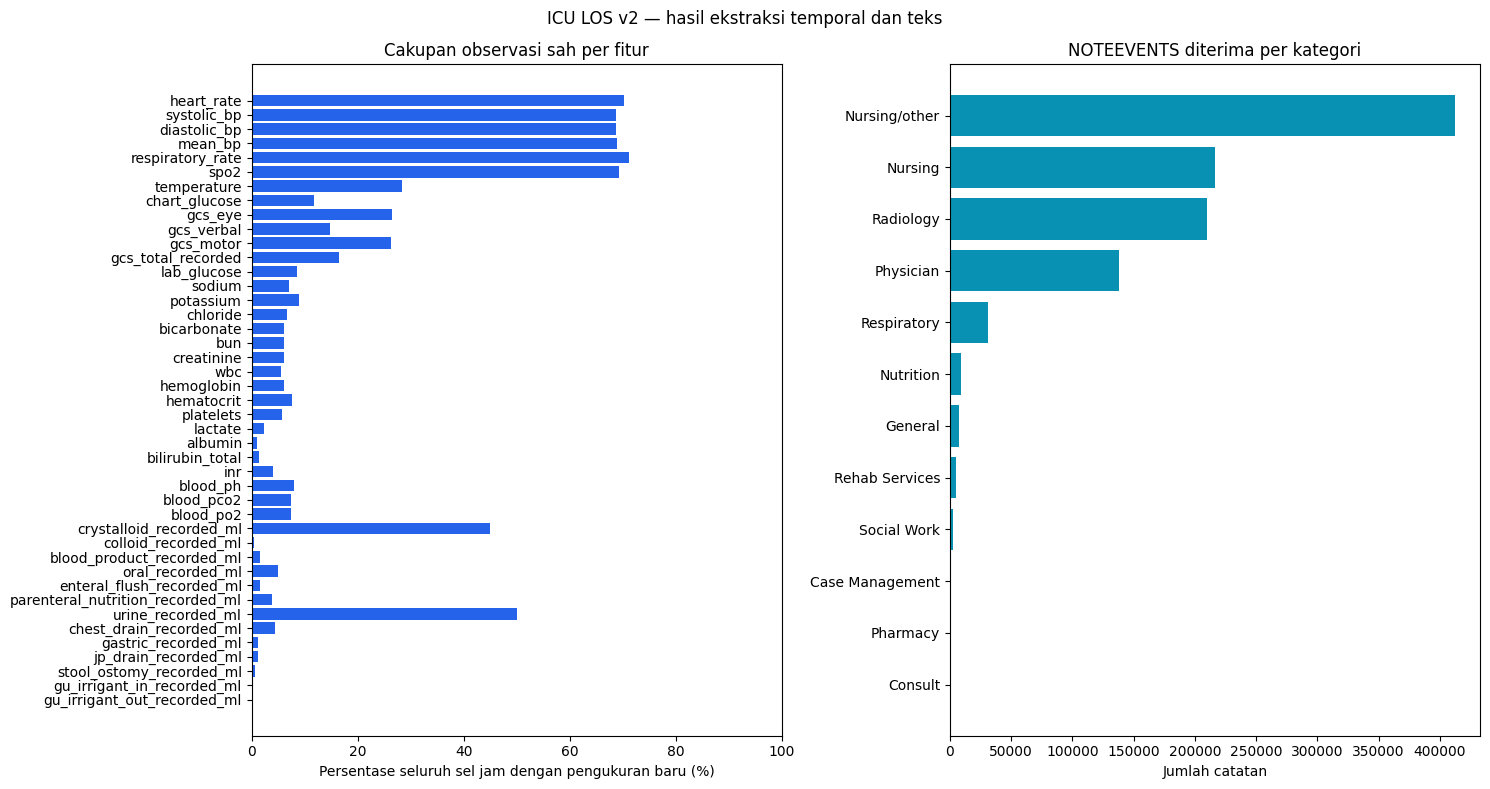

ICU LOS v2 — STAGE02 SEQUENCE BUILD
Run: 20261019_140043_593718_sequences
STAGE01: 20261019_134016_937053_cohort
Cohort stays: 53,044; unique patients: 38,398
Hourly slots: 5,279,187; temporal features: 43; partitions: 415
Eligible hourly prediction points: 5,120,055
Notes accepted: 1,033,980; duplicate content retained: 31,335
X_static and y remain separate Stage01 artifacts; target not read for event processing.
No fixed 24/48h window. Use prefix strictly before each prediction time; never expose final sequence length.
No imputation, normalization, split, tokenization, BERT embedding, graph or model training.
All partition aggregations checked against SQL; clinical time proxies and retained LOS/disposition content remain limitations.
Checks: 11 PASS; 0 FAIL.
Status: SEQUENCES_COMPLETE_READY_FOR_SPLIT_PREPROCESS
Data: C:\Users\ASUS\Documents\icu_los\data\20261019_140043_593718_sequences
Reports: C:\Users\ASUS\Documents\icu_los\outputs\20261019_140043_593718_sequences


In [12]:
fig,axes=plt.subplots(1,2,figsize=(15,8))
layout=pd.DataFrame(FEATURE_LAYOUT,columns=['variable','aggregation','unit'])
p=layout.merge(feature_profile,on='variable',how='left')
p['missing_hour_percentage']=p.missing_hour_percentage.fillna(100)
axes[0].barh(p.variable,100-p.missing_hour_percentage,color='#2563eb')
axes[0].invert_yaxis();axes[0].set(title='Cakupan observasi sah per fitur',xlabel='Persentase seluruh sel jam dengan pengukuran baru (%)',xlim=(0,100))
if not note_profile.empty:
    q=note_profile.sort_values('notes')
    axes[1].barh(q.category,q.notes,color='#0891b2')
    axes[1].set(title='NOTEEVENTS diterima per kategori',xlabel='Jumlah catatan')
else:
    axes[1].text(.5,.5,'Tidak ada notes diterima',ha='center',va='center',transform=axes[1].transAxes)
    axes[1].set_title('NOTEEVENTS')
fig.suptitle('ICU LOS v2 — hasil ekstraksi temporal dan teks')
fig.tight_layout()
fig.savefig(report_dir/'sequence_overview.png',dpi=180,bbox_inches='tight')
fig.savefig(report_dir/'sequence_overview.svg',bbox_inches='tight')
plt.show()
print((report_dir/'summary.txt').read_text(encoding='utf-8'))

## 12. Hasil untuk tahap 03
**Bagikan hanya** `summary.txt`, `quality_checks.csv`, `sequence_counts.csv`, dan jika perlu laporan agregat `processing_counts.csv`. Jangan bagikan SQLite, partisi `_LOCAL`, atau preview teks/ID.

Berkas penting:
- `run_metadata.json`: status, hash kohort, sumber, kode runtime, ledger dan database.
- `sequence_contract.json`: lokasi X statis/y yang terpisah, 43 fitur, aturan waktu dan batas penggunaan metadata.
- `sequences_LOCAL.sqlite`: observasi deduplikasi, provenance lokal, notes mentah dan checkpoint chunk.
- `temporal/part_XXXXX_LOCAL.npz`: `values`, mask, count dan offsets per stay. ID dan offsets hanya metadata pengaitan.
- `sequence_index_LOCAL.csv`: hubungan stay dan partisi, bukan fitur model.

### Batas pekerjaan
Pemeriksaan SQL memverifikasi penyimpanan dan persamaan agregasi; bukan bukti timestamp proxy sama dengan waktu ketersediaan klinis. Tidak ada imputasi, fitting, tokenizer, embedding, graf, training atau evaluasi test. Pembobotan titik prediksi per stay dan batch prefix ditetapkan sebelum training agar stay panjang tidak mendominasi tanpa sengaja.

### Referensi sumber aturan
Pemetaan/quality/aggregation dipertahankan dari build temporal v1 dan dicocokkan pada PC pengguna. Kode port berasal dari `step04_temporal_review_v3.py` (11 Oktober 2026); tidak mengklaim seluruh batas sudah tervalidasi klinis.
- MIMIC-III ICUSTAYS: https://mimic.mit.edu/docs/iii/tables/icustays.html
- INPUTEVENTS_MV: https://mimic.mit.edu/docs/iii/tables/inputevents_mv.html
- INPUTEVENTS_CV: https://mimic.mit.edu/docs/iii/tables/inputevents_cv.html
- NOTEEVENTS: https://mimic.mit.edu/docs/iii/tables/noteevents.html
- Aturan kualitas yang diwariskan: DOI 10.1038/s41597-021-00864-4; 10.1093/jalm/jfae021; 10.1016/j.jbi.2019.103269. Adaptasi dan batas yang belum selesai direview tercantum dalam fungsi `reference_quality_policy()`.